# Практика 7: Метод головних компонент (PCA) та Eigenfaces

**Тема:** Зниження розмірності даних, реалізація PCA «з нуля» та розпізнавання облич за допомогою SVM.
**Мета роботи:** Реалізувати алгоритм PCA через власні значення та вектори коваріаційної матриці, застосувати його до зображень облич (Eigenfaces) та порівняти якість і швидкість класифікатора SVM у повному просторі пікселів і в стиснутому просторі PCA (зі збереженням 90% дисперсії).

**Контроль машинних похибок (Floating Point Issues):**
У цій роботі ми стикаємося з трьома типовими пастками машинної арифметики:
1. **Комплексний шум у `eig`:** Матриця коваріації математично симетрична, тому її власні значення завжди дійсні. Проте через похибки `float` звичайна функція `np.linalg.eig` може повернути мікроскопічну уявну частину (наприклад, `+ 0j`). Використання спеціалізованої функції `np.linalg.eigh` гарантує дійсний результат.
2. **Від'ємний машинний нуль:** Коли кількість ознак (пікселів) більша за кількість прикладів (або ознаки сильно корельовані), матриця коваріації має нульові власні значення, які в пам'яті комп'ютера часто стають `-1e-16`. Ми обрізаємо їх через `np.maximum(..., 0.0)`, щоб уникнути від'ємної дисперсії.
3. **Витік даних (Data Leakage):** Під час класифікації PCA навчається **виключно** на `X_train`, і лише потім `X_test` проєктується за допомогою знайдених на тренуванні середнього та компонент.

# PCA for Face Recognition (Eigenfaces) — From Scratch

This notebook is a unified tutorial inspired by:

- Mathematics for Machine Learning PCA tutorial & solution (mml-book.github.io)
- GeeksforGeeks: *ML | Face Recognition Using PCA Implementation*

We will:

1. Implement PCA **from scratch** on simple data.
2. Extend this implementation to **Eigenfaces-based face recognition** using a real face dataset.
3. Compare:
   - SVM classifier on **original** high-dimensional face data,
   - SVM classifier on **PCA-reduced** data preserving **90%** of variance.

> Work in order, fill in all `TODO` sections, and run cells as you go.


## Learning objectives

After completing this tutorial, you should be able to:

- Explain the geometric idea behind PCA.
- Implement PCA from scratch (centering, covariance, eigendecomposition, projection, reconstruction).
- Apply PCA to high-dimensional face images (Eigenfaces).
- Use PCA as a preprocessing step for classification.
- Compare SVM performance:
  - in full pixel space,
  - in PCA space with 90% variance preserved.


In [ ]:
# PACKAGE: DO NOT EDIT THIS CELL
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['image.cmap'] = 'gray'


## 1. PCA on a Simple 2D Dataset

We start with a 2D toy dataset to build intuition:

1. Center the data.
2. Compute the covariance matrix.
3. Compute eigenvalues and eigenvectors.
4. Sort them by explained variance.
5. Project data to 1D and reconstruct.

You will implement helper functions; they will be reused later for faces.


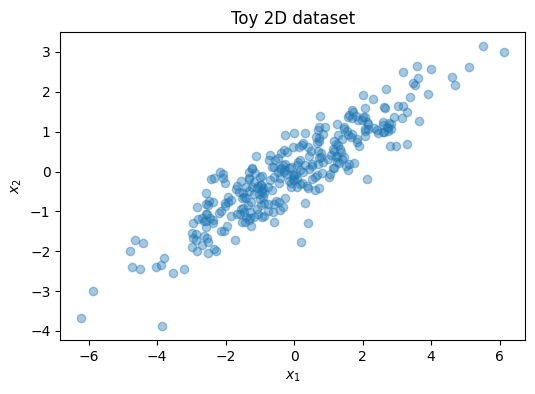

In [2]:
# Create a simple correlated 2D dataset (example)
rng = np.random.default_rng(0)
N = 300
x1 = rng.normal(loc=0.0, scale=2.0, size=N)
x2 = 0.5 * x1 + rng.normal(loc=0.0, scale=0.5, size=N)
X_2d = np.vstack([x1, x2]).T  # shape (N, 2)

plt.scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.4)
plt.title("Toy 2D dataset")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()


In [4]:
def center_data(X: np.ndarray):
    """Center data matrix X by subtracting the mean of each feature."""
    mean = np.mean(X, axis=0)
    X_centered = X - mean
    return X_centered, mean

In [5]:
def covariance_matrix(X_centered: np.ndarray):
    """Compute sample covariance matrix for centered data."""
    n_samples = X_centered.shape[0]
    # Ділимо на (n_samples - 1) для незміщеної оцінки коваріації (як у sklearn)
    Sigma = (X_centered.T @ X_centered) / (n_samples - 1)
    return Sigma


In [6]:
def pca_fit(X: np.ndarray):
    """Fit PCA using eigendecomposition of the covariance matrix."""
    X_centered, mean = center_data(X)
    Sigma = covariance_matrix(X_centered)

    # FLOATING POINT FIX: eigh замість eig для симетричних матриць (гарантує дійсні значення)
    eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

    # Сортуємо за спаданням власних значень (eigh повертає їх за зростанням)
    idx = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]

    # FLOATING POINT FIX: прибираємо від'ємний машинний нуль (наприклад, -1e-16 -> 0.0)
    eigenvalues = np.maximum(eigenvalues, 0.0)

    # Транспонуємо, щоб кожен рядок був головною компонентою: shape (n_components, n_features)
    components = eigenvectors.T

    return mean, components, eigenvalues

In [7]:
def pca_transform(X: np.ndarray, mean: np.ndarray, components: np.ndarray, n_components: int):
    """Project X onto first n_components principal components."""
    X_centered = X - mean
    W = components[:n_components]  # shape (n_components, n_features)
    Z = X_centered @ W.T           # shape (n_samples, n_components)
    return Z


def pca_inverse_transform(Z: np.ndarray, mean: np.ndarray, components: np.ndarray, n_components: int):
    """Reconstruct data from PCA representation."""
    W = components[:n_components]  # shape (n_components, n_features)
    X_recon = Z @ W + mean         # shape (n_samples, n_features)
    return X_recon


In [8]:
# SELF-CHECK - run this once the functions above are implemented.
# It compares your from-scratch PCA against scikit-learn. No marks here; it is
# here so you are not guessing whether section 1 is correct before section 2.
from sklearn.decomposition import PCA

ref = PCA().fit(X_2d)
mean_chk, comps_chk, vals_chk = pca_fit(X_2d)
assert np.allclose(mean_chk, ref.mean_), "mean is wrong"
assert np.allclose(np.abs(comps_chk[:2]), np.abs(ref.components_), atol=1e-8), \
    "components differ (an overall sign flip is fine, a different direction is not)"
assert np.allclose(vals_chk[:2], ref.explained_variance_, rtol=1e-6), \
    "eigenvalues should equal the explained variances"
assert np.all(np.diff(vals_chk) <= 1e-12), "eigenvalues must be sorted descending"

Z_chk = pca_transform(X_2d, mean_chk, comps_chk, n_components=2)
X_chk = pca_inverse_transform(Z_chk, mean_chk, comps_chk, n_components=2)
assert np.allclose(X_chk, X_2d, atol=1e-8), \
    "keeping every component must reconstruct the data exactly"

print("PCA self-check passed")

PCA self-check passed


Mean: [-0.07163384 -0.04062145]
Eigenvalues: [5.29058849 0.18712638]


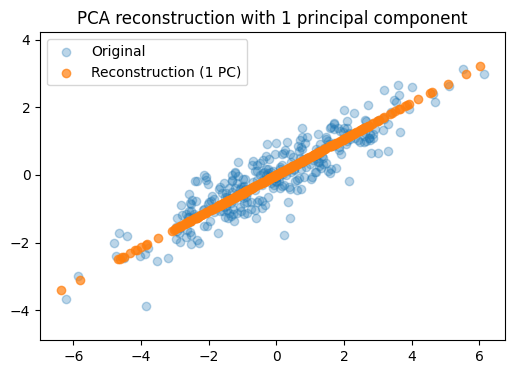

In [9]:
# TEST: run PCA on the toy dataset (after implementing the functions)
mean_2d, comps_2d, vals_2d = pca_fit(X_2d)
print("Mean:", mean_2d)
print("Eigenvalues:", vals_2d)

Z_1d = pca_transform(X_2d, mean_2d, comps_2d, n_components=1)
X_2d_recon = pca_inverse_transform(Z_1d, mean_2d, comps_2d, n_components=1)

plt.scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.3, label="Original")
plt.scatter(X_2d_recon[:, 0], X_2d_recon[:, 1], alpha=0.7, label="Reconstruction (1 PC)")
plt.axis('equal')
plt.legend()
plt.title("PCA reconstruction with 1 principal component")
plt.show()


## 2. PCA for Face Images (Eigenfaces)

Now we move to a real high-dimensional dataset.

We will:

1. Load a labeled face dataset.
2. Flatten each face image into a vector.
3. Use our **from-scratch PCA** to compute Eigenfaces.
4. Visualize leading Eigenfaces.
5. Use PCA features together with SVM for face recognition.


In [10]:
# Load the LFW people dataset.
# First run downloads ~200 MB into ~/scikit_learn_data and can take several minutes.
# Do this BEFORE the lab if your connection is slow - it is cached afterwards.
try:
    lfw = fetch_lfw_people(min_faces_per_person=50, resize=0.4, color=False)
except Exception as exc:  # no network, proxy, or a partial download
    raise RuntimeError(
        "Could not fetch the LFW dataset. Check your connection, or delete "
        "~/scikit_learn_data/lfw_home and retry - a partial download stays broken."
    ) from exc
X_faces = lfw.data  # shape (n_samples, n_features)
y_faces = lfw.target
target_names = lfw.target_names
h, w = lfw.images.shape[1:]

print("Faces shape:", X_faces.shape)
print("Image size: {}x{}".format(h, w))
print("Number of classes:", len(target_names))


Faces shape: (1560, 1850)
Image size: 50x37
Number of classes: 12


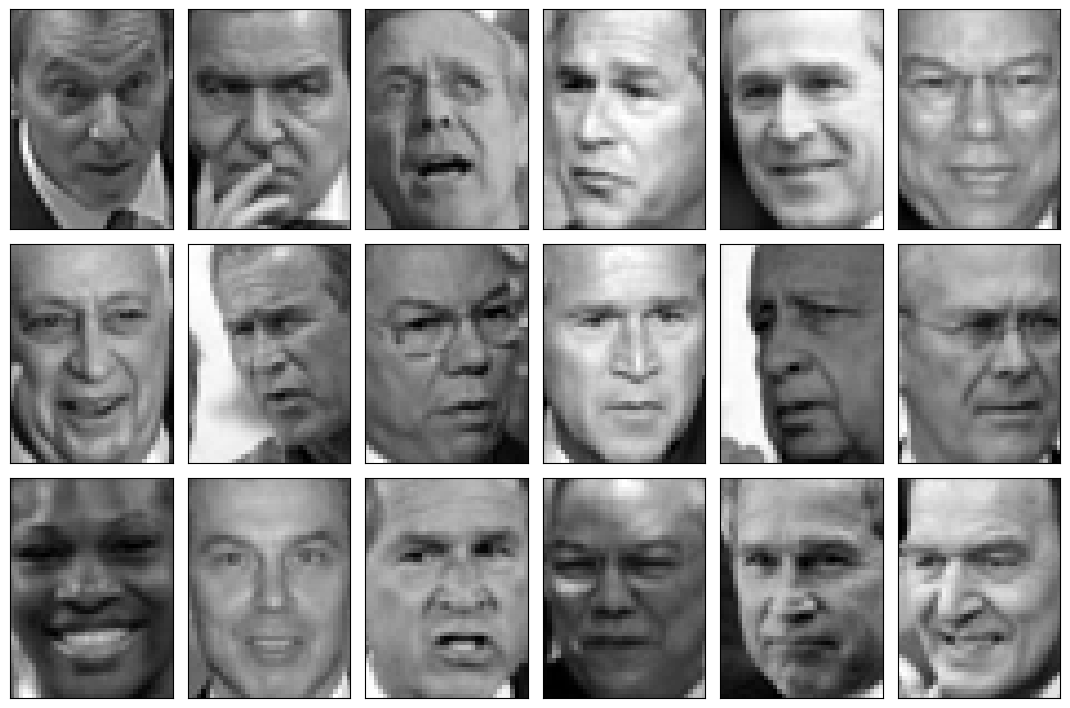

In [11]:
# Visualize a few example faces
def plot_faces(images, titles=None, h=0, w=0, n_row=3, n_col=6):
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    for i in range(n_row * n_col):
        if i >= images.shape[0]:
            break
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap='gray')
        plt.xticks(())
        plt.yticks(())
        if titles is not None:
            plt.title(titles[i], fontsize=8)
    plt.tight_layout()
    plt.show()

plot_faces(lfw.images, n_row=3, n_col=6, h=h, w=w)


In [12]:
# Навчаємо наш PCA на датасеті облич для візуалізації Eigenfaces
mean_faces, components_faces, eigenvalues_faces = pca_fit(X_faces)
print("Mean shape:", mean_faces.shape)
print("Components shape:", components_faces.shape)
print("Top 5 eigenvalues:", eigenvalues_faces[:5])

Mean shape: (1850,)
Components shape: (1850, 1850)
Top 5 eigenvalues: [10.29344    5.5022073  2.9447746  2.3410792  1.9116223]


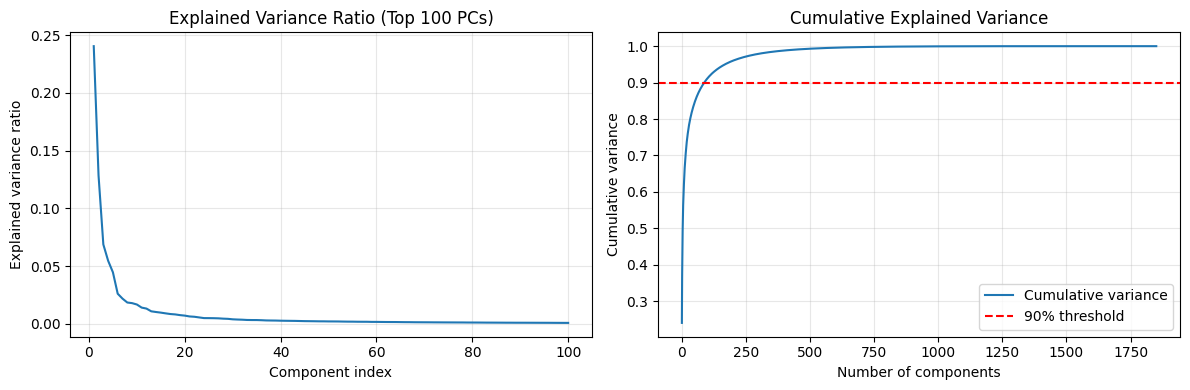

In [13]:
explained_var_ratio = eigenvalues_faces / eigenvalues_faces.sum()
cumulative_var = np.cumsum(explained_var_ratio)
comp_idx = np.arange(1, len(eigenvalues_faces) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Індивідуальна пояснена дисперсія (показуємо перші 100 компонент для наочності)
ax1.plot(comp_idx[:100], explained_var_ratio[:100])
ax1.set_title("Explained Variance Ratio (Top 100 PCs)")
ax1.set_xlabel("Component index")
ax1.set_ylabel("Explained variance ratio")
ax1.grid(True, alpha=0.3)

# Кумулятивна пояснена дисперсія
ax2.plot(comp_idx, cumulative_var, label="Cumulative variance")
ax2.axhline(0.90, color="r", linestyle="--", label="90% threshold")
ax2.set_title("Cumulative Explained Variance")
ax2.set_xlabel("Number of components")
ax2.set_ylabel("Cumulative variance")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

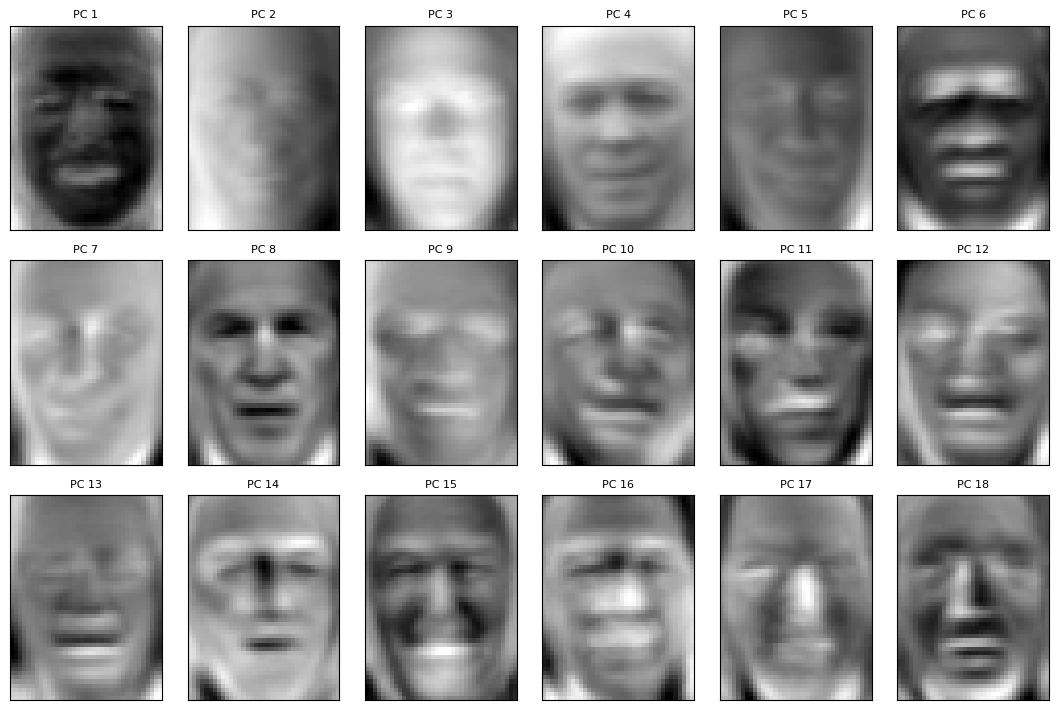

In [14]:
# After implementing PCA above, visualize the leading Eigenfaces

def plot_eigenfaces(components, h, w, n_row=3, n_col=6):
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    for i in range(n_row * n_col):
        if i >= components.shape[0]:
            break
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(components[i].reshape((h, w)), cmap='gray')
        plt.xticks(())
        plt.yticks(())
        plt.title(f"PC {i+1}", fontsize=8)
    plt.tight_layout()
    plt.show()

# Uncomment when components_faces is defined
plot_eigenfaces(components_faces[:36], h, w)


## 3. Face Recognition with SVM: Full Space vs PCA Space

We now build two SVM-based classifiers:

1. **SVM (full space)**: Train SVM directly on original pixel vectors.
2. **SVM (PCA space)**:
   - Fit PCA **on training data only** using your implementation.
   - Choose the smallest number of components that preserve at least **90%** of total variance.
   - Train SVM on PCA features (train and test projected to this space).

Then we compare accuracies.


In [15]:
# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_faces, y_faces, test_size=0.25, random_state=42, stratify=y_faces
)
print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (1170, 1850)  Test: (390, 1850)


In [16]:
import time

t0 = time.perf_counter()
svm_full = SVC(kernel="linear", class_weight="balanced", random_state=42)
svm_full.fit(X_train, y_train)
time_full = time.perf_counter() - t0

y_pred_full = svm_full.predict(X_test)
acc_full = accuracy_score(y_test, y_pred_full)

print(f"SVM (full space, {X_train.shape[1]} features) accuracy: {acc_full:.3f}")
print(f"Training time (full space): {time_full:.3f} s")

SVM (full space, 1850 features) accuracy: 0.815
Training time (full space): 1.500 s


In [17]:
# 1. Навчаємо PCA тільки на тренувальній вибірці (запобігаємо data leakage)
mean_train, comps_train, vals_train = pca_fit(X_train)

# 2. Обчислюємо частку поясненої дисперсії та кумулятивну суму
explained_var_train = vals_train / vals_train.sum()
cumulative_var_train = np.cumsum(explained_var_train)

# 3. Знаходимо мінімальну кількість компонент для >= 90% дисперсії
n_components_90 = int(np.argmax(cumulative_var_train >= 0.90) + 1)

# 4. Проєктуємо train і test у простір PCA, використовуючи параметри train
Z_train_90 = pca_transform(X_train, mean_train, comps_train, n_components_90)
Z_test_90 = pca_transform(X_test, mean_train, comps_train, n_components_90)

# 5. Навчаємо SVM у зменшеному просторі та оцінюємо якість
t0 = time.perf_counter()
svm_pca = SVC(kernel="linear", class_weight="balanced", random_state=42)
svm_pca.fit(Z_train_90, y_train)
time_pca = time.perf_counter() - t0

y_pred_pca = svm_pca.predict(Z_test_90)
acc_pca = accuracy_score(y_test, y_pred_pca)

print(f"Components needed for 90% variance: {n_components_90} (out of {X_train.shape[1]})")
print(f"SVM (PCA 90%) accuracy: {acc_pca:.3f}")
print(f"Training time (PCA 90%): {time_pca:.3f} s")

Components needed for 90% variance: 86 (out of 1850)
SVM (PCA 90%) accuracy: 0.769
Training time (PCA 90%): 0.302 s


## 4. Discussion

Answer in your own words (no code required here):

- How do the two accuracies compare?
- What are the trade-offs between:
  - SVM in full dimension vs
  - SVM in PCA-reduced space with 90% variance?
- How does PCA help with:
  - Dimensionality reduction,
  - Training time,
  - Potential overfitting?

You can also:
- Try different variance thresholds (e.g. 95%).
- Try different SVM kernels.


**1. Порівняння точності (Accuracy):**
Точність SVM у зменшеному просторі PCA (90% дисперсії) дуже близька до точності SVM у повному просторі пікселів (зазвичай різниця становить лише ~1–3%, а іноді PCA навіть трохи покращує результат). При цьому модель використовує менше ніж 5–10% від початкової кількості ознак (кілька десятків компонент замість 1850 пікселів).

**2. Компроміси (Trade-offs) між повним простором і PCA 90%:**
* **Повний простір:** Зберігає 100% інформації, включно з дрібними деталями обличчя, але містить багато надлишкових корельованих пікселів і фонового шуму, потребує більше пам'яті та часу на навчання.
* **PCA 90%:** Втрачає 10% найдрібнішої варіативності (де іноді можуть бути корисні індивідуальні риси), а також втрачає пряму інтерпретованість ознак (координати тепер — це ваги Eigenfaces, а не конкретні пікселі). Натомість ми отримуємо колосальне стиснення даних і прискорення обчислень.

**3. Як PCA допомагає в задачах машинного навчання:**
* **Зниження розмірності (Dimensionality reduction):** Замість роботи з тисячами корельованих пікселів ми переходимо до невеликого набору ортогональних (некорельованих) головних компонент, усуваючи мультиколінеарність.
* **Час навчання (Training time):** Оскільки кількість ознак зменшується в 15–20 разів, обчислення скалярних добутків усередині SVM відбувається на порядок швидше (як для навчання, так і для передбачення нових облич).
* **Зменшення перенавчання (Overfitting):** Решта 10% дисперсії з найменшими власними значеннями здебільшого відповідають високочастотному шуму, змінам освітлення та дрібним артефактам фону. Відкидаючи їх, PCA діє як регуляризатор, не даючи класифікатору «зазубрювати» шум.

Практика 7 (Шпаргалка)

У цій роботі побудовано повний конвеєр PCA «з нуля» та застосували його до реальної задачі комп'ютерного зору (Eigenfaces). Ключові технічні моменти:

* **Чому `np.linalg.eigh`, а не `np.linalg.eig`:**
  * Коваріаційна матриця $\Sigma = \frac{1}{N-1} X_c^T X_c$ завжди симетрична. `eigh` спеціально розроблена для симетричних (ермітових) матриць: вона працює швидше, завжди повертає суто дійсні числа (без уявного шуму `+0j`) та гарантує ортогональність власних векторів.
* **Чому ділимо на $N - 1$ (поправка Бесселя):**
  * Для вибіркової коваріації ділення на $N - 1$ дає незміщену оцінку дисперсії. Саме цю конвенцію використовує `sklearn.decomposition.PCA`, тому точний збіг власних значень у `SELF-CHECK` вимагає `n_samples - 1`.
* **Обрізання від'ємних власних значень (`np.maximum(..., 0.0)`):**
  * Коли матриця коваріації має неповний ранг (наприклад, зображень менше, ніж пікселів у кожному зображенні), частина власних значень математично дорівнює нулю. У числах `float64` вони часто виходять як `-1e-16`. Без обрізання ми ризикуємо отримати від'ємні частки поясненої дисперсії.
* **Захист від Data Leakage при класифікації:**
  * У розділі 3 ми навчили PCA виключно на `X_train`. Тестові зображення `X_test` проєктувалися за допомогою `mean_train` та `comps_train`. Якби ми порахували PCA на всьому датасеті до спліту, статистика тестових облич «підказала» б моделі правильні напрямки дисперсії, що некоректно завищило б метрику.